# Librerias

In [1]:
# Librerias
import numpy as np
from astropy.io import fits
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
import time

# import MUSE_utils.PPXF_astrometry_correction as ppxf_ac
# import MUSE_utils.PPXF_class as ppxf_c
# import MUSE_utils.PPXF_extinction_correction as ppxf_ec
import MUSE_utils.PPXF_fitting as ppxf_f
import MUSE_utils.PPXF_helper as ppxf_h
# import MUSE_utils.PPXF_redshift_calculator as ppxf_rc
# import MUSE_utils.PPXF_zapping as ppxf_z

import joblib
from tqdm import tqdm
from joblib import Parallel, delayed

/home/humonthief/Universidad/Magister/MUSE PKS0745/MUSE_utils/PPXF_fitting.py:208: SyntaxWarning: invalid escape sequence '\s'
  txt = f"Voronoi bin {j+1} / {nbins}; SPS: {sps_name}; $\sigma$={sigbin_j:.0f} km/s; S/N={pp_stars.sn:.1f}"
/home/humonthief/Universidad/Magister/MUSE PKS0745/MUSE_utils/PPXF_fitting.py:20: UserWarning: ⚠️ VorBin is deprecated and superseded by PowerBin https://pypi.org/project/powerbin/ 
  from vorbin.voronoi_2d_binning import voronoi_2d_binning



Map_clipping line: Hbeta

Map_clipping line: Halpha

Weighted used

Map_clipping line: [SII]6716

Map_clipping line: [SII]6731

Map_clipping line: HeII4687

Map_clipping line: HeI5876

Map_clipping line: [NII]5755

Map_clipping line: [NI]5198

Map_clipping line: [NI]5200

Map_clipping line: [OIII]5007_d

Map_clipping line: [OI]6300_d

Map_clipping line: [NII]6583_d


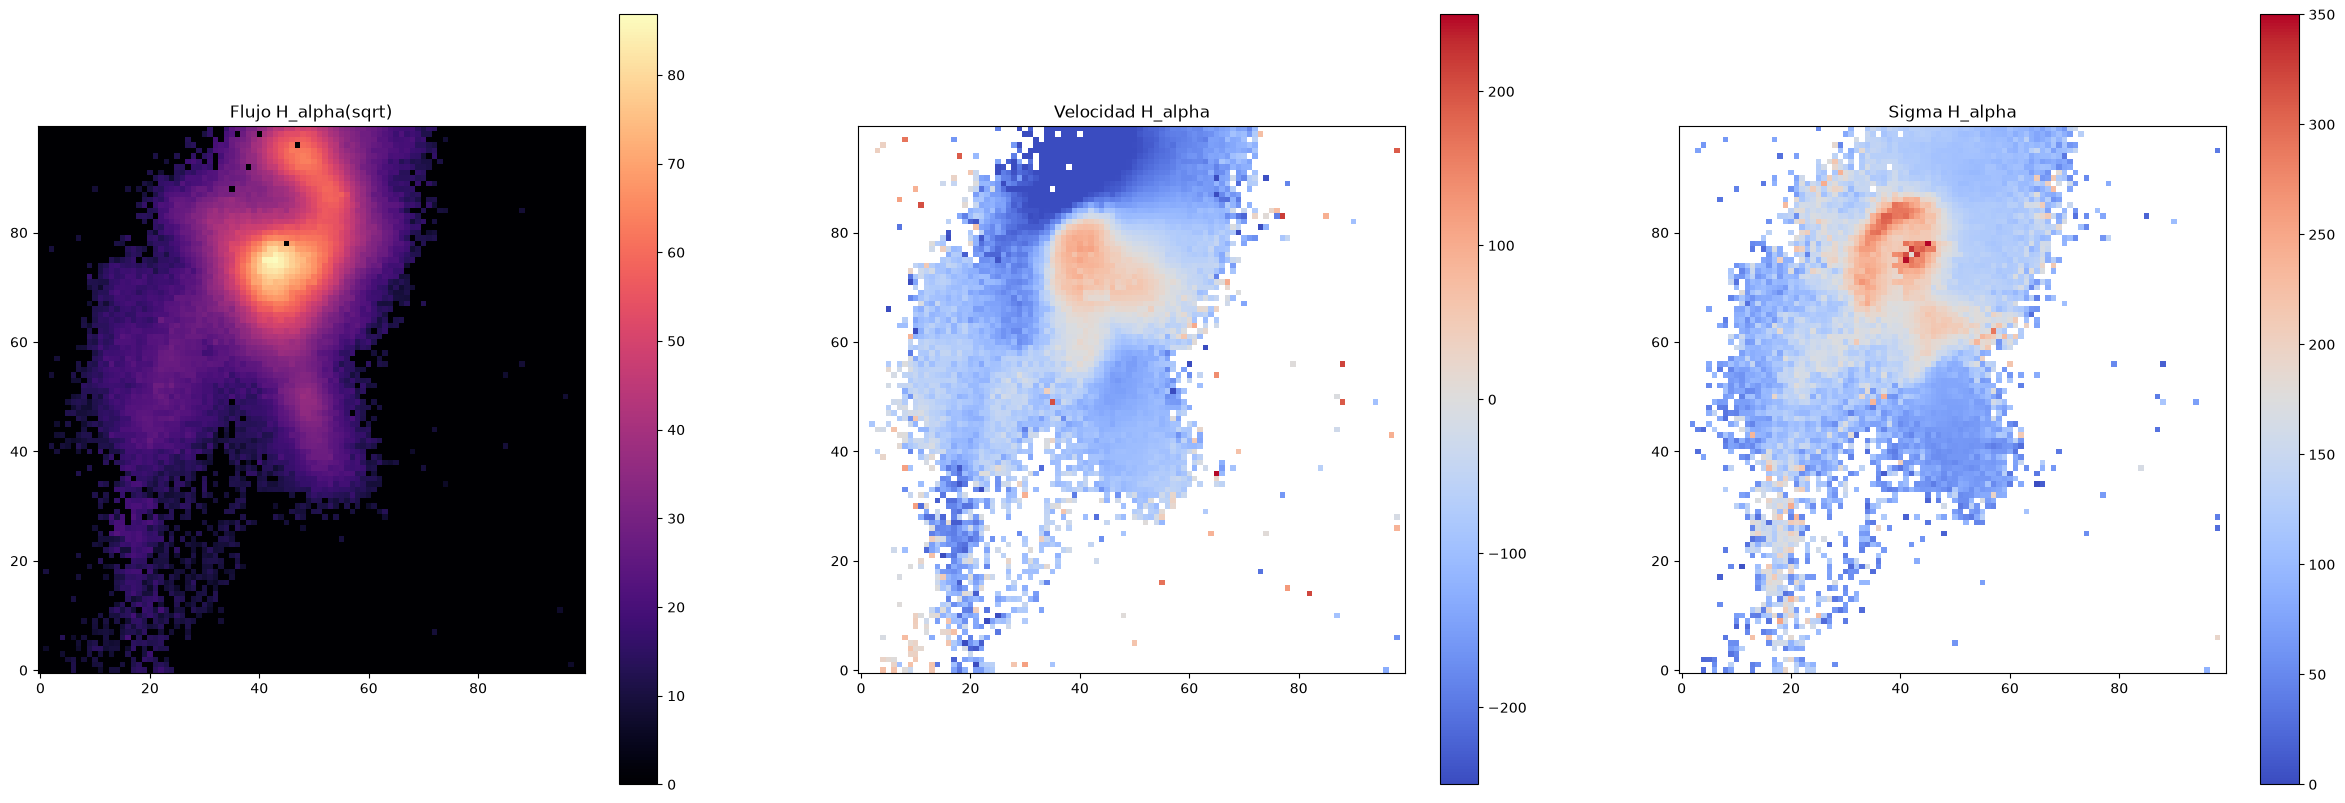

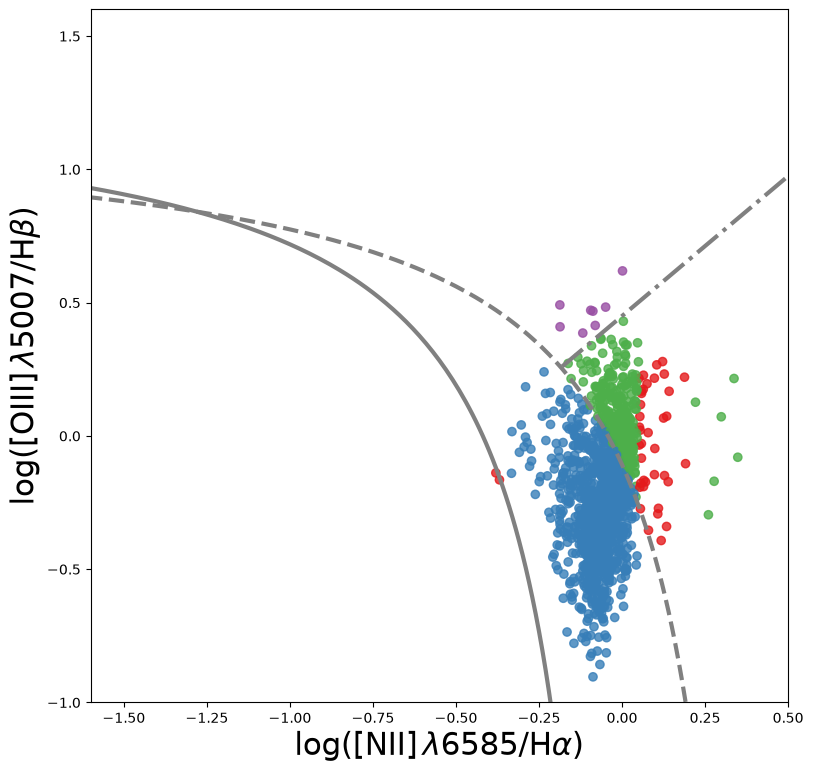

In [2]:
wave_map = {'Hbeta': np.float64(4861.33297684225),
            'Halpha': np.float64(6562.8190214441065),
            '[SII]6716': np.float64(6716.439708128853),
            '[SII]6731': np.float64(6730.815840542734),
            'HeII4687': np.float64(4685.703527762145),
            'HeI5876': np.float64(5875.614442651756),
            '[NII]5755': np.float64(5753.404160629015),
            '[NI]5198': np.float64(5196.452876247093),
            '[NI]5200': np.float64(5198.812247803875),
            '[OIII]5007_d': np.float64(5006.843330296288),
            '[OI]6300_d': np.float64(6300.297553341503),
            '[NII]6583_d': np.float64(6583.452474108442)}

ppxf_f.GasKinematicsFitter.Clip_maps(wave_map = wave_map, name_fits_properties = "maps_ABELL/MUSE_PKS0745_properties.fits", min_vel_err=60, min_sigma_err=40, max_snr=2.7)

with fits.open("maps_ABELL/MUSE_PKS0745_properties.fits") as hdu:
    NII_f = hdu["[NII]6583_D_MAP_FLUX_CLIPPED"].data
    OIII_f = hdu["[OIII]5007_D_MAP_FLUX_CLIPPED"].data
    H_alpha_f = hdu["HALPHA_MAP_FLUX_CLIPPED"].data
    H_alpha_f_e = hdu["HALPHA_FLUX_ERR_WEIGHTED"].data
    H_alpha_v = hdu["HALPHA_MAP_VEL_CLIPPED"].data
    H_alpha_s = hdu["HALPHA_MAP_SIGMA_CLIPPED"].data
    H_beta_f = hdu["HBETA_MAP_FLUX_CLIPPED"].data
mask = (NII_f != 0) & (H_alpha_f != 0)

fig, ax = plt.subplots(1,3,figsize=(30,10))
im0 = ax[0].imshow(np.sqrt(H_alpha_f)*mask,origin='lower',interpolation='nearest', cmap="magma")
ax[0].set_title("Flujo H_alpha(sqrt)")
fig.colorbar(im0, ax=ax[0])

mask = H_alpha_f/H_alpha_f

im1 = ax[1].imshow(H_alpha_v*mask,vmin=-250,vmax=250,cmap='coolwarm',origin='lower',interpolation='nearest')
ax[1].set_title("Velocidad H_alpha")
fig.colorbar(im1, ax=ax[1])

im2 = ax[2].imshow(H_alpha_s*mask,vmin=0,vmax=350,cmap='coolwarm',origin='lower',interpolation='nearest')
ax[2].set_title("Sigma H_alpha")
fig.colorbar(im2, ax=ax[2])
fig.show()

#fig, ax = plt.subplots(1,1,figsize=(10,10))

#im1 = ax[1].imshow(np.sqrt(H_alpha_f_e), cmap="magma",origin='lower',interpolation='nearest')
#ax[1].set_title("Error del flujo H_alpha")
#fig.colorbar(im1, ax=ax[1])
#fig.show()

# BPT DIAGRAM

x = NII_f/H_alpha_f /1.33
y = OIII_f/H_beta_f /1.33
#plt.scatter(np.log10(y),np.log10(x))
#plt.show()

fig, ax = plt.subplots(figsize=(9,9))

t = np.arange(-2.0,0.3,0.01)
l = np.arange(-2.0,0.0,0.01)
s = np.arange(-0.18, 1.5, 0.01)

from palettable.colorbrewer.qualitative import Set1_4 as brewermap
from matplotlib.colors import ListedColormap

select_SF = (np.log10(y)<(0.61/(np.log10(x)-0.05)+1.3)) & (np.log10(x)<0.2)
select_inter = (np.log10(y)<(0.61/(np.log10(x)-0.47)+1.19)) & (np.log10(x)<0.2) & (select_SF==False)
# select_liner = (np.log10(y)<(np.log10(x)+0.43)/np.cos(59*np.pi/180.0)-0.49) &        (select_SF==False) & (select_inter==False)
# select_AGN = (np.log10(y)>(np.log10(x)+0.43)/np.cos(59*np.pi/180.0)-0.49) & (select_SF==False) & (select_inter==False)
select_liner = (np.log10(y)<(1.05 * np.log10(x)+0.45)) & (select_SF==False) & (select_inter==False)
select_AGN = (np.log10(y)>(1.05 * np.log10(x)+0.45)) & (select_SF==False) & (select_inter==False)
excitation = np.zeros_like(x)
excitation[select_SF] = 1
excitation[select_inter] = 2
excitation[select_liner] = 3
excitation[select_AGN] = 4
excitation[excitation==0.0] = np.nan

cmap = ListedColormap(brewermap.mpl_colors)

ax.scatter(np.log10(x),np.log10(y), cmap=cmap, c=excitation, alpha=0.8) #  

ax.plot(t,(0.61/(t-0.47)+1.19),'--',color='gray',linewidth=3,label='Kewley et al. (2001)',zorder=1)
ax.plot(l,(0.61/(l-0.05)+1.3),'-',color='gray',linewidth=3,label='Kauffmann et al. (2003)',zorder=1)
# ax.plot(s, s+0.43/np.cos(59*np.pi/180.0)-0.49)
ax.plot(s, (1.05*s + 0.45),'-.',color='gray',linewidth=3,label='Schawinski et al. (2007)',zorder=1)
ax.set_xlim([-1.6, 0.5])
ax.set_ylim([ -1.0, 1.6])
ax.set_ylabel(r'$\log(\mathrm{[O III]}\,\lambda 5007 / \mathrm{H}\beta)$',fontsize=22)
ax.set_xlabel(r'$\log(\mathrm{[N II]}\,\lambda 6585 / \mathrm{H}\alpha)$',fontsize=22)
fig.show()

In [ ]:
with fits.open("H_ALPHA_FLUX.fits") as hdu:
    H_alpha_f_vale = hdu[0].data
with fits.open("H_BETA_FLUX.fits") as hdu:
    H_beta_f_vale = hdu[0].data
with fits.open("NII_6584_FLUX.fits") as hdu:
    NII_f_vale = hdu[0].data
with fits.open("OIII_5007_FLUX.fits") as hdu:
    OIII_f_vale = hdu[0].data

x = NII_f_vale/H_alpha_f_vale
y = OIII_f_vale/H_beta_f_vale 
#plt.scatter(np.log10(y),np.log10(x))
#plt.show()

fig, ax = plt.subplots(figsize=(9,9))

t = np.arange(-2.0,0.3,0.01)
l = np.arange(-2.0,0.0,0.01)
s = np.arange(-0.18, 1.5, 0.01)

from palettable.colorbrewer.qualitative import Set1_4 as brewermap
from matplotlib.colors import ListedColormap

select_SF = (np.log10(y)<(0.61/(np.log10(x)-0.05)+1.3)) & (np.log10(x)<0.2)
select_inter = (np.log10(y)<(0.61/(np.log10(x)-0.47)+1.19)) & (np.log10(x)<0.2) & (select_SF==False)
# select_liner = (np.log10(y)<(np.log10(x)+0.43)/np.cos(59*np.pi/180.0)-0.49) &        (select_SF==False) & (select_inter==False)
# select_AGN = (np.log10(y)>(np.log10(x)+0.43)/np.cos(59*np.pi/180.0)-0.49) & (select_SF==False) & (select_inter==False)
select_liner = (np.log10(y)<(1.05 * np.log10(x)+0.45)) & (select_SF==False) & (select_inter==False)
select_AGN = (np.log10(y)>(1.05 * np.log10(x)+0.45)) & (select_SF==False) & (select_inter==False)
excitation = np.zeros_like(x)
excitation[select_SF] = 1
excitation[select_inter] = 2
excitation[select_liner] = 3
excitation[select_AGN] = 4
excitation[excitation==0.0] = np.nan

cmap = ListedColormap(brewermap.mpl_colors)

ax.scatter(np.log10(x),np.log10(y), cmap=cmap, c=excitation, alpha=0.8) #  

ax.plot(t,(0.61/(t-0.47)+1.19),'--',color='gray',linewidth=3,label='Kewley et al. (2001)',zorder=1)
ax.plot(l,(0.61/(l-0.05)+1.3),'-',color='gray',linewidth=3,label='Kauffmann et al. (2003)',zorder=1)
# ax.plot(s, s+0.43/np.cos(59*np.pi/180.0)-0.49)
ax.plot(s, (1.05*s + 0.45),'-.',color='gray',linewidth=3,label='Schawinski et al. (2007)',zorder=1)
ax.set_xlim([-1.6, 0.5])
ax.set_ylim([ -1.0, 1.6])
ax.set_ylabel(r'$\log(\mathrm{[O III]}\,\lambda 5007 / \mathrm{H}\beta)$',fontsize=22)
ax.set_xlabel(r'$\log(\mathrm{[N II]}\,\lambda 6585 / \mathrm{H}\alpha)$',fontsize=22)
fig.show()